## **Maestría en Inteligencia Artificial Aplicada**
### **Curso: Inteligencia Artificial y Aprendizaje Automático**
#### Tecnológico de Monterrey
#### Prof Luis Eduardo Falcón Morales

### **Actividad de la Semana: Sistemas de Recomendación basados en factorización SVD y Agentes**


**Esta Actividad deberá resolverse de manera individual.**

* **Nombre:** Ricardo Saldaña Morales

* **Matrícula:** A01841000



**Incluye todas las librerías y líneas de código que consideres adecuadas.**

In [1]:
import numpy as np
import pandas as pd

import re
import json
import textwrap
import matplotlib.pyplot as plt

from scipy.sparse import csr_matrix
from sklearn.decomposition import TruncatedSVD
from sklearn.model_selection import train_test_split
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import StandardScaler, normalize

# **Ejercicio - 1: cargando datos**

In [2]:
# Se suben las tablas movies.dat, ratings.dat y users.dat.

RUTA = '/content/'

def leer_dat(archivo, columnas):
    try:
        return pd.read_csv(RUTA + archivo, sep='::', engine='python', names=columnas, encoding='utf-8')
    except UnicodeDecodeError:
        return pd.read_csv(RUTA + archivo, sep='::', engine='python', names=columnas, encoding='latin-1')

movies  = leer_dat('movies.dat',  ['MovieID', 'Title', 'Genres'])
users   = leer_dat('users.dat',   ['UserID', 'Gender', 'Age', 'Occupation', 'Zip'])
ratings = leer_dat('ratings.dat', ['UserID', 'MovieID', 'Rating', 'Timestamp'])

for nombre, df in [('movies', movies), ('users', users), ('ratings', ratings)]:
    print(f'{nombre:8s}: {df.shape[0]:>9,} renglones x {df.shape[1]} columnas | nulos: {df.isnull().sum().sum()} | duplicados: {df.duplicated().sum()}')

movies  :     3,883 renglones x 3 columnas | nulos: 0 | duplicados: 0
users   :     6,040 renglones x 5 columnas | nulos: 0 | duplicados: 0
ratings : 1,000,209 renglones x 4 columnas | nulos: 0 | duplicados: 0


In [3]:
display(movies.head())
display(users.head())
display(ratings.head())

,MovieID,Title,Genres
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama
4,5,Father of the Bride Part II (1995),Comedy


,UserID,Gender,Age,Occupation,Zip
0,1,F,1,10,48067
1,2,M,56,16,70072
2,3,M,25,15,55117
3,4,M,45,7,02460
4,5,M,25,20,55455


,UserID,MovieID,Rating,Timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968
3,1,3408,4,978300275
4,1,2355,5,978824291


In [4]:
# 1a. Se obtiene la cantidad de usuarios, películas y calificaciones
n_usuarios = ratings['UserID'].nunique()
n_peliculas = movies['MovieID'].nunique()
n_peliculas_evaluadas = ratings['MovieID'].nunique()
n_evaluaciones = len(ratings)

print(f'Usuarios en users.dat                  : {users["UserID"].nunique():,}')
print(f'Usuarios con evaluaciones              : {n_usuarios:,}')
print(f'Películas en movies.dat                : {n_peliculas:,}')
print(f'Películas con al menos una evaluación  : {n_peliculas_evaluadas:,}')
print(f'Películas sin ninguna evaluación       : {n_peliculas - n_peliculas_evaluadas:,}')
print(f'Evaluaciones en ratings.dat            : {n_evaluaciones:,}')
print(f'Pares usuario-película repetidos       : {ratings.duplicated(["UserID", "MovieID"]).sum()}')

Usuarios en users.dat                  : 6,040
Usuarios con evaluaciones              : 6,040
Películas en movies.dat                : 3,883
Películas con al menos una evaluación  : 3,706
Películas sin ninguna evaluación       : 177
Evaluaciones en ratings.dat            : 1,000,209
Pares usuario-película repetidos       : 0


Valores de calificación: [1, 2, 3, 4, 5]
Mínimo: 1 | Máximo: 5 | Promedio: 3.58 | Mediana: 4


,Evaluaciones,Porcentaje (%)
Rating,,
1,56174,5.62
2,107557,10.75
3,261197,26.11
4,348971,34.89
5,226310,22.63


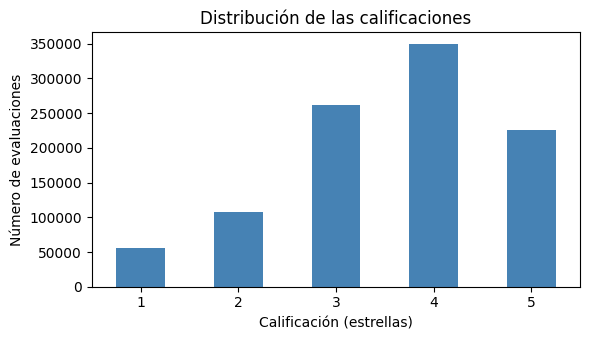

In [5]:
# 1b. Se observa la distribución de las calificaciones
print('Valores de calificación:', sorted(ratings['Rating'].unique().tolist()))
print(f'Mínimo: {ratings["Rating"].min()} | Máximo: {ratings["Rating"].max()} | Promedio: {ratings["Rating"].mean():.2f} | Mediana: {ratings["Rating"].median():.0f}')

dist = ratings['Rating'].value_counts().sort_index()
display(pd.DataFrame({'Evaluaciones': dist, 'Porcentaje (%)': (100 * dist / dist.sum()).round(2)}))

dist.plot(kind='bar', color='steelblue', figsize=(6, 3.5))
plt.title('Distribución de las calificaciones')
plt.xlabel('Calificación (estrellas)')
plt.ylabel('Número de evaluaciones')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

a. Existen 6,040 usuarios, 3,883 películas en el catálogo (movies.dat) y 1,000,209 evaluaciones (ratings.dat). Se observa que solo 3,706 películas tienen al menos una evaluación y las otras 177 nadie las calificó. Con esto la matriz de utilidad considerará solo las 3,706. Además, no hay valores nulos ni repetidos, y todos los usuarios de users.dat tienen evaluaciones.

b. Las películas se califican de 1 a 5 estrellas con números enteros del 1 al 5. La distribución está concentrada hacia la derecha en donde el 4 es la calificación con mayor frecuencia (34.89%), el promedio es 3.58 y aproximadamente el 16% de las evaluaciones son menores o iguales a 2. Probablemente las personas tienden a ver y calificar películas que ya esperaban que les gustaran.

# **Ejercicio - 2: matriz de utilidad**

In [6]:
# Se define la matriz de utilidad considerando solo las que tienen calificación (3,706)
user_ids  = np.sort(ratings['UserID'].unique())
movie_ids = np.sort(ratings['MovieID'].unique())
idx_usuario  = pd.Series(np.arange(len(user_ids)),  index=user_ids)
idx_pelicula = pd.Series(np.arange(len(movie_ids)), index=movie_ids)

filas = ratings['UserID'].map(idx_usuario).values
cols  = ratings['MovieID'].map(idx_pelicula).values

R = csr_matrix((ratings['Rating'].values.astype(np.float64), (filas, cols)),
               shape=(len(user_ids), len(movie_ids)))

celdas = R.shape[0] * R.shape[1]
densidad = R.nnz / celdas
dispersion = 1 - densidad

print(f'Dimensión de la matriz de utilidad: {R.shape[0]:,} usuarios x {R.shape[1]:,} películas')
print(f'Celdas totales        : {celdas:,}')
print(f'Celdas con calificación: {R.nnz:,}')
print(f'Densidad              : {densidad:.4%}')
print(f'Dispersión (sparsity) : {dispersion:.4%}')

Dimensión de la matriz de utilidad: 6,040 usuarios x 3,706 películas
Celdas totales        : 22,384,240
Celdas con calificación: 1,000,209
Densidad              : 4.4684%
Dispersión (sparsity) : 95.5316%


In [7]:
# Se revisan 10 usuarios y las 6 películas más evaluadas
top6 = ratings['MovieID'].value_counts().index[:6]
vista = pd.DataFrame(R[:10][:, idx_pelicula[top6].values].toarray(), index=user_ids[:10],
                     columns=movies.set_index('MovieID').loc[top6, 'Title']).replace(0, np.nan)
vista.index.name = 'UserID'
display(vista)

# Se obtienen la cantidad de evaluaciones por usuario y por película
por_usuario  = ratings.groupby('UserID').size()
por_pelicula = ratings.groupby('MovieID').size()
display(pd.DataFrame({'Evaluaciones por usuario': por_usuario.describe(),
                      'Evaluaciones por película': por_pelicula.describe()}).round(1))
print(f'En promedio cada usuario calificó el {por_usuario.mean() / R.shape[1]:.1%} de las películas')
print(f'Películas con menos de 20 evaluaciones: {(por_pelicula < 20).sum()} ({(por_pelicula < 20).mean():.1%})')

mem_densa = celdas * 8 / 1024**2
mem_csr = (R.data.nbytes + R.indices.nbytes + R.indptr.nbytes) / 1024**2
print(f'\nMemoria como matriz densa (float64): {mem_densa:,.1f} MB')
print(f'Memoria en formato disperso CSR    : {mem_csr:,.1f} MB')

Title,American Beauty (1999),Star Wars: Episode IV - A New Hope (1977),Star Wars: Episode V - The Empire Strikes Back (1980),Star Wars: Episode VI - Return of the Jedi (1983),Jurassic Park (1993),Saving Private Ryan (1998)
UserID,,,,,,
1,NaN,4.0,NaN,NaN,NaN,5.0
2,4.0,NaN,5.0,4.0,5.0,4.0
3,4.0,5.0,4.0,4.0,4.0,NaN
4,NaN,5.0,2.0,3.0,4.0,5.0
5,4.0,NaN,NaN,NaN,NaN,2.0
6,1.0,NaN,NaN,3.0,NaN,NaN
7,NaN,NaN,5.0,NaN,4.0,5.0
8,5.0,NaN,NaN,4.0,5.0,5.0
9,4.0,NaN,NaN,4.0,4.0,5.0


,Evaluaciones por usuario,Evaluaciones por película
count,6040.0,3706.0
mean,165.6,269.9
std,192.7,384.0
min,20.0,1.0
25%,44.0,33.0
50%,96.0,123.5
75%,208.0,350.0
max,2314.0,3428.0


En promedio cada usuario calificó el 4.5% de las películas
Películas con menos de 20 evaluaciones: 663 (17.9%)

Memoria como matriz densa (float64): 170.8 MB
Memoria en formato disperso CSR    : 11.5 MB


a. Se obtuvo la matriz de utilidad con los usuarios en los renglones y las películas en las columnas, con una dimensión de 6,040 x 3,706 (22,384,240 celdas). De esas celdas solo 1,000,209 tienen calificación, por lo que la densidad es de 4.47% y la dispersión (sparsity) de 95.53%.

b. Una dispersión de 95.53% nos dice que de cada 100 combinaciones usuario-película, en aproximadamente 95 no sabemos qué opina el usuario. En promedio cada persona calificó 166 películas, apenas el 4.5% del catálogo, y la mediana es menor (96). Por otra parte, hay películas con más de 3,000 evaluaciones y 663 películas (17.9%) con menos de 20.

c. Las principales consideraciones que veo son:

- En cuanto a la memoria, la matriz densa ocupa unos 171 MB y en formato disperso CSR solo 11.5 MB. Con catálogos reales de millones de usuarios y productos la versión densa no cabría en memoria, por ello se ocupa scipy.sparse.

- Es preferible usar métodos como TruncatedSVD de sklearn que trabajen directamente sobre matrices dispersas ya que solo calculan las k componentes que se necesitan. Una SVD completa sobre la matriz densa es mucho más costosa en tiempo y memoria.

- Las películas con muy pocas calificaciones tienen factores poco confiables, y para usuarios o películas nuevas no hay con qué factorizar.

# **Ejercicio - 3: varianza explicada y número de componentes latentes**

In [8]:
# Previo a factorizar, se centra cada calificación con el promedio de su usuario.
prom_usuario = ratings.groupby('UserID')['Rating'].mean()
centradas = ratings['Rating'] - ratings['UserID'].map(prom_usuario)
R_centrada = csr_matrix((centradas.values, (filas, cols)), shape=R.shape)

# Se factoriza la transpuesta (películas x usuarios) para obtener la información latente de las películas
X_peliculas = R_centrada.T.tocsr()
print('Matriz que se factoriza (películas x usuarios):', X_peliculas.shape)
print('Número máximo posible de componentes:', min(X_peliculas.shape))

Matriz que se factoriza (películas x usuarios): (3706, 6040)
Número máximo posible de componentes: 3706


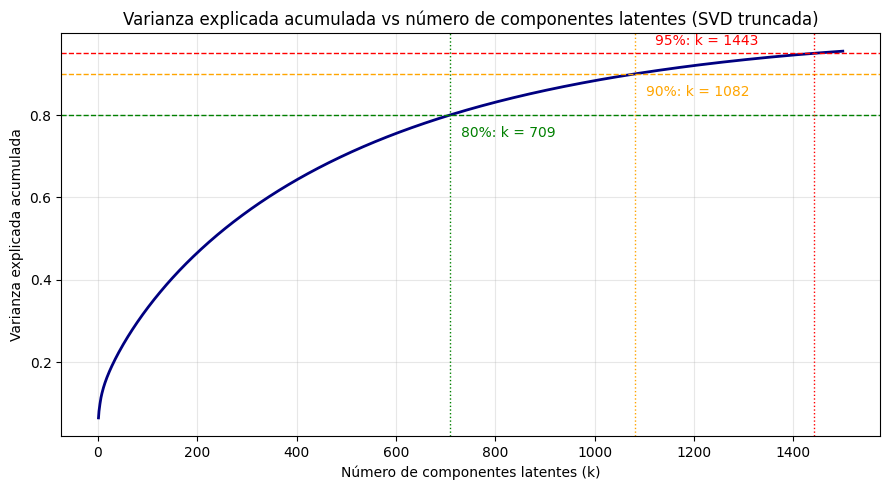

In [9]:
# SVD truncada con 1,500 componentes
svd_var = TruncatedSVD(n_components=1500, random_state=42)
svd_var.fit(X_peliculas)
var_acum = np.cumsum(svd_var.explained_variance_ratio_)

umbrales = [0.80, 0.90, 0.95]
k_umbral = {u: int(np.argmax(var_acum >= u) + 1) for u in umbrales}

# 3a. Gráfica de varianza explicada acumulada
plt.figure(figsize=(9, 5))
plt.plot(np.arange(1, len(var_acum) + 1), var_acum, color='navy', lw=2)
for u, c in zip(umbrales, ['green', 'orange', 'red']):
    plt.axhline(u, ls='--', color=c, lw=1)
    plt.axvline(k_umbral[u], ls=':', color=c, lw=1)
    plt.annotate(f'{u:.0%}: k = {k_umbral[u]}', (k_umbral[u], u), xytext=(8, -16) if u < 0.95 else (-115, 6),
                 textcoords='offset points', color=c)
plt.title('Varianza explicada acumulada vs número de componentes latentes (SVD truncada)')
plt.xlabel('Número de componentes latentes (k)')
plt.ylabel('Varianza explicada acumulada')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
# 3b. Componentes necesarias para 80%, 90% y 95%
display(pd.DataFrame({'Varianza acumulada': [f'{u:.0%}' for u in umbrales],
                      'Componentes necesarias (k)': [k_umbral[u] for u in umbrales],
                      '% del máximo posible (3,706)': [f'{k_umbral[u] / min(X_peliculas.shape):.1%}' for u in umbrales]}).set_index('Varianza acumulada'))

print('Varianza que explica la 1a componente :', f'{svd_var.explained_variance_ratio_[0]:.2%}')
for k in [10, 20, 50, 100, 500]:
    print(f'Varianza acumulada con k = {k:>3}      : {var_acum[k - 1]:.2%}')

,Componentes necesarias (k),"% del máximo posible (3,706)"
Varianza acumulada,,
80%,709,19.1%
90%,1082,29.2%
95%,1443,38.9%


Varianza que explica la 1a componente : 6.45%
Varianza acumulada con k =  10      : 13.37%
Varianza acumulada con k =  20      : 16.87%
Varianza acumulada con k =  50      : 24.11%
Varianza acumulada con k = 100      : 33.17%
Varianza acumulada con k = 500      : 70.46%


a. Se obtiene la gráfica de la varianza explicada acumulada contra el número de componentes latentes de la SVD truncada con hasta 1,500 componentes.

b. Se necesitan 709 componentes para el 80% de la varianza, 1,082 para el 90% y 1,443 para el 95%, que equivalen al 19%, 29% y 39% de las 3,706 dimensiones posibles.

c. La curva no presenta un codo claramente definido, lo que dificulta identificar un número de componentes a partir del cual la varianza explicada deje de aumentar considerablemente. Esto puede estar relacionado con la diversidad de preferencias de los usuarios y la alta dispersión de la matriz, aunque no es posible determinarlo únicamente a partir de la gráfica.

Se observa que con k = 709 se alcanza el 80% de la varianza explicada, pero para llegar al 90% se requieren 373 componentes adicionales y otros 361 para alcanzar el 95%. Esto muestra que cada vez se necesitan más componentes para obtener incrementos menores en la varianza acumulada.

Sin embargo, 709 componentes representan una cantidad considerable para un modelo cuyo objetivo es resumir la información en pocos factores latentes. Además, es importante considerar que la varianza explicada mide la información estadística que conservan los componentes respecto de la matriz utilizada, pero no permite determinar directamente qué tan bien se predicen las calificaciones de los usuarios. Por ello, este criterio se utilizará como referencia para compararlo posteriormente con el RMSE.

# **Ejercicio - 4: métrica RMSE y número de componentes latentes**



In [11]:
# 4a. División 80% entrenamiento / 20% prueba
train, test = train_test_split(ratings, test_size=0.2, random_state=42)
print(f'Entrenamiento: {len(train):,} evaluaciones | Prueba: {len(test):,} evaluaciones')
print(f'Usuarios de prueba que también están en entrenamiento : {test["UserID"].isin(train["UserID"]).mean():.2%}')
print(f'Películas de prueba que también están en entrenamiento: {test["MovieID"].isin(train["MovieID"]).mean():.2%}')

# Se obtiene la matriz de entrenamiento centrada con el promedio de cada usuario calculado solo para train
prom_usuario_train = train.groupby('UserID')['Rating'].mean()
X_train = csr_matrix(((train['Rating'] - train['UserID'].map(prom_usuario_train)).values,
                      (train['MovieID'].map(idx_pelicula).values, train['UserID'].map(idx_usuario).values)),
                     shape=(len(movie_ids), len(user_ids)))

i_test = test['MovieID'].map(idx_pelicula).values
u_test = test['UserID'].map(idx_usuario).values
base_test = test['UserID'].map(prom_usuario_train).values
y_test = test['Rating'].values

def rmse(y, y_pred):
    return np.sqrt(np.mean((y - y_pred) ** 2))

def predecir(P, Q, k):
    ajuste = np.zeros(len(i_test))
    for ini in range(0, len(i_test), 50_000):
        b = slice(ini, ini + 50_000)
        ajuste[b] = np.einsum('ij,ji->i', P[i_test[b], :k], Q[:k, u_test[b]])
    return np.clip(base_test + ajuste, 1, 5)

rmse_base = rmse(y_test, np.clip(base_test, 1, 5))
print(f'\nRMSE de referencia usando solo el promedio de cada usuario (k = 0): {rmse_base:.4f}')

Entrenamiento: 800,167 evaluaciones | Prueba: 200,042 evaluaciones
Usuarios de prueba que también están en entrenamiento : 100.00%
Películas de prueba que también están en entrenamiento: 99.99%

RMSE de referencia usando solo el promedio de cada usuario (k = 0): 1.0394


In [12]:
# 4b. Se entrena el modelo SVD con el k que sugería la varianza explicada (80%) y se evalua en prueba
k_var = k_umbral[0.80]
svd_k = TruncatedSVD(n_components=k_var, random_state=42)
P_k = svd_k.fit_transform(X_train)     # factores latentes de las películas
Q_k = svd_k.components_                # factores latentes de los usuarios
print(f'RMSE en el conjunto de prueba con k = {k_var}: {rmse(y_test, predecir(P_k, Q_k, k_var)):.4f}')

RMSE en el conjunto de prueba con k = 709: 1.0289


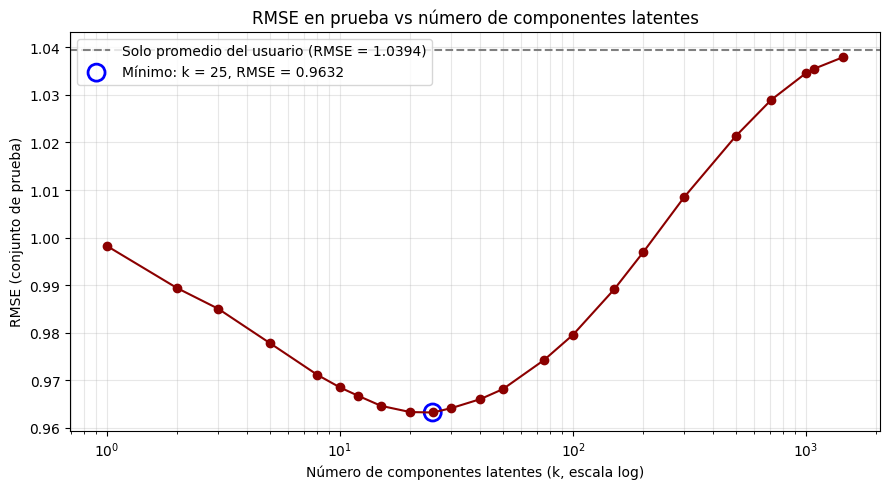

k,1,2,3,5,8,10,12,15,20,25,...,75,100,150,200,300,500,709,1000,1082,1443
RMSE,0.9982,0.9894,0.9851,0.9778,0.9711,0.9685,0.9667,0.9646,0.9633,0.9632,...,0.9742,0.9796,0.9891,0.9969,1.0085,1.0214,1.029,1.0346,1.0355,1.0379


In [13]:
# 4c. RMSE contra el número de componentes
k_max = 1500
svd_train = TruncatedSVD(n_components=k_max, random_state=42)
P_train = svd_train.fit_transform(X_train)
Q_train = svd_train.components_

valores_k = sorted(set([1, 2, 3, 5, 8, 10, 12, 15, 20, 25, 30, 40, 50, 75, 100, 150, 200, 300, 500, 1000] + list(k_umbral.values())))
tabla_rmse = pd.DataFrame({'k': valores_k, 'RMSE': [rmse(y_test, predecir(P_train, Q_train, k)) for k in valores_k]})
k_min_rmse = int(tabla_rmse.loc[tabla_rmse['RMSE'].idxmin(), 'k'])

plt.figure(figsize=(9, 5))
plt.plot(tabla_rmse['k'], tabla_rmse['RMSE'], 'o-', color='darkred')
plt.axhline(rmse_base, ls='--', color='gray', label=f'Solo promedio del usuario (RMSE = {rmse_base:.4f})')
plt.scatter([k_min_rmse], [tabla_rmse['RMSE'].min()], s=150, facecolors='none', edgecolors='blue', lw=2,
            label=f'Mínimo: k = {k_min_rmse}, RMSE = {tabla_rmse["RMSE"].min():.4f}')
plt.xscale('log')
plt.title('RMSE en prueba vs número de componentes latentes')
plt.xlabel('Número de componentes latentes (k, escala log)')
plt.ylabel('RMSE (conjunto de prueba)')
plt.legend()
plt.grid(alpha=0.3, which='both')
plt.tight_layout()
plt.show()

display(tabla_rmse.set_index('k').T.round(4))

a. Se realizó la partición en entrenamiento y prueba, donde se observa que todos los usuarios de prueba aparecen en entrenamiento y solo el 0.01% de las evaluaciones de prueba son de películas que no están en entrenamiento, para esos casos la predicción queda como el promedio del usuario.

b. La predicción de una calificación es el promedio del usuario (calculado solo con entrenamiento) más la reconstrucción de la SVD truncada, recortada a la escala de 1 a 5. Con k = 709, el valor que salía del criterio de varianza, el RMSE en prueba es 1.0289, prácticamente igual que no usar SVD y predecir solo con el promedio del usuario (1.0394). Con muchas componentes el modelo no aporta.

c. Se obtiene la gráfica de RMSE contra k (en escala logarítmica) en donde se observa que el error baja rápido entre 1 y 20 componentes, llega a su mínimo entre 20 y 25, y de ahí sube de forma constante hasta 1.0379 con 1,443 componentes.

d. El mínimo exacto está en k = 25 con RMSE = 0.9632, pero con k = 20 el RMSE es 0.9633. Dado que la diferencia es mínima, se selecciona k = 20. Con menos componentes el modelo no alcanza a capturar los patrones (subajuste) y con más empieza a aprender el ruido de entrenamiento (sobreajuste).

# **Ejercicio - 5: comparación varianza explicada vs RMSE**

,k,Varianza explicada,RMSE prueba
Criterio,,,
Varianza explicada 80%,709,80.0%,1.0290
Varianza explicada 90%,1082,90.0%,1.0355
Varianza explicada 95%,1443,95.0%,1.0379
Mínimo RMSE,25,18.3%,0.9632
Seleccionado,20,16.9%,0.9633


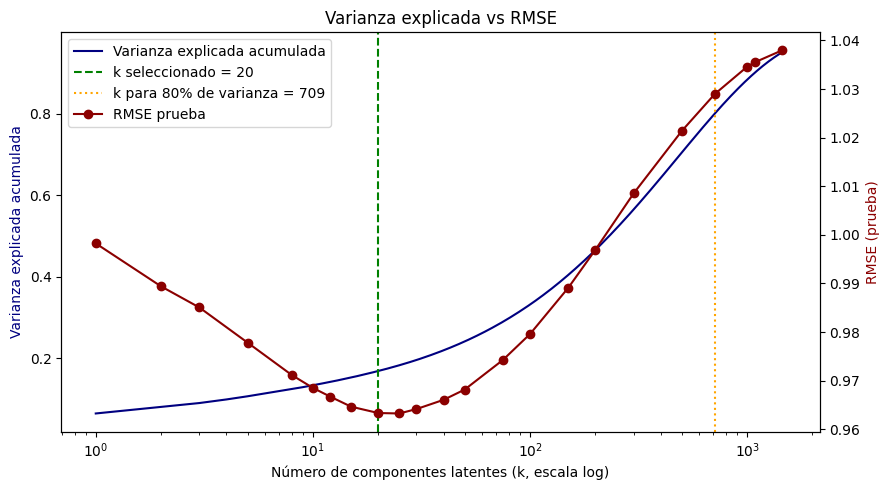

In [14]:
K = 20   # número de componentes latentes seleccionados

rmse_de = dict(zip(tabla_rmse['k'], tabla_rmse['RMSE']))
comparacion = pd.DataFrame({
    'Criterio': ['Varianza explicada 80%', 'Varianza explicada 90%', 'Varianza explicada 95%', 'Mínimo RMSE', 'Seleccionado'],
    'k': [k_umbral[0.80], k_umbral[0.90], k_umbral[0.95], k_min_rmse, K]})
comparacion['Varianza explicada'] = [f'{var_acum[k - 1]:.1%}' for k in comparacion['k']]
comparacion['RMSE prueba'] = [round(rmse_de[k], 4) for k in comparacion['k']]
display(comparacion.set_index('Criterio'))

fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(np.arange(1, k_max + 1), var_acum[:k_max], color='navy', label='Varianza explicada acumulada')
ax1.set_xscale('log')
ax1.set_xlabel('Número de componentes latentes (k, escala log)')
ax1.set_ylabel('Varianza explicada acumulada', color='navy')
ax2 = ax1.twinx()
ax2.plot(tabla_rmse['k'], tabla_rmse['RMSE'], 'o-', color='darkred', label='RMSE prueba')
ax2.set_ylabel('RMSE (prueba)', color='darkred')
ax1.axvline(K, color='green', ls='--', label=f'k seleccionado = {K}')
ax1.axvline(k_umbral[0.80], color='orange', ls=':', label=f'k para 80% de varianza = {k_umbral[0.80]}')
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax2.legend(h1 + h2, l1 + l2, loc='upper left')
plt.title('Varianza explicada vs RMSE')
fig.tight_layout()
plt.show()

Se observa que los dos criterios presentan resultados muy distintos. Mientras que la varianza explicada requiere 709 componentes para alcanzar el 80%, el RMSE presenta sus mejores resultados con aproximadamente 20 a 25 componentes. Esta diferencia se debe a que ambos criterios evalúan aspectos distintos del modelo: la varianza explicada mide la proporción de variabilidad capturada por los factores latentes, mientras que el RMSE permite evaluar qué tan bien se predicen las calificaciones que el modelo no utilizó durante su entrenamiento.

En la gráfica combinada se observa que, mientras la varianza explicada continúa aumentando, el RMSE comienza a empeorar después de aproximadamente 25 componentes. Por ejemplo, con 709 componentes se alcanza el 80% de la varianza explicada, pero se obtiene un RMSE de 1.0290, superior al de 0.9633 obtenido con 20 componentes.

Por esta razón, se selecciona k = 20, que presenta un desempeño predictivo prácticamente igual al mínimo observado con 25 componentes, pero utilizando menos factores latentes. Aunque este valor únicamente captura el 16.9% de la varianza de la matriz utilizada, permite obtener mejores predicciones en los datos de prueba que los valores de k asociados con mayores porcentajes de varianza explicada. Además, se obtiene una representación más compacta de las películas, lo que favorece la eficiencia computacional del sistema.

# **Ejercicio - 6: sistema de recomendación colaborativo**

In [15]:
# SVD truncada final con K componentes sobre toda la matriz
svd = TruncatedSVD(n_components=K, random_state=42)
factores_peliculas = svd.fit_transform(X_peliculas)
print('Factores latentes de las películas:', factores_peliculas.shape)

# 6a. Se obtiene la matriz de similitud del coseno entre los factores latentes de las películas
sim_svd = cosine_similarity(factores_peliculas)

# 6b. Dimensión de la matriz
print('Dimensión de la matriz de similitud:', sim_svd.shape)

info = movies.set_index('MovieID').loc[movie_ids].reset_index()
info['Year'] = info['Title'].str.extract(r'\((\d{4})\)\s*$')[0].astype(int)
info['NumEvaluaciones'] = ratings.groupby('MovieID').size().loc[movie_ids].values
info['Promedio'] = ratings.groupby('MovieID')['Rating'].mean().loc[movie_ids].round(2).values
idx_titulo = pd.Series(info.index, index=info['Title'])

muestra = [idx_titulo[t] for t in ['Toy Story (1995)', 'Toy Story 2 (1999)', 'Matrix, The (1999)',
                                   'Terminator 2: Judgment Day (1991)', 'Pretty Woman (1990)']]
display(pd.DataFrame(sim_svd[np.ix_(muestra, muestra)], index=info.loc[muestra, 'Title'],
                     columns=info.loc[muestra, 'Title']).round(3))

Factores latentes de las películas: (3706, 20)
Dimensión de la matriz de similitud: (3706, 3706)


Title,Toy Story (1995),Toy Story 2 (1999),"Matrix, The (1999)",Terminator 2: Judgment Day (1991),Pretty Woman (1990)
Title,,,,,
Toy Story (1995),1.000,0.948,0.512,0.440,0.154
Toy Story 2 (1999),0.948,1.000,0.497,0.426,0.087
"Matrix, The (1999)",0.512,0.497,1.000,0.808,0.103
Terminator 2: Judgment Day (1991),0.440,0.426,0.808,1.000,0.236
Pretty Woman (1990),0.154,0.087,0.103,0.236,1.000


In [16]:
def buscar(texto):
    # función para encontrar el título exacto de una película
    return info.loc[info['Title'].str.contains(texto, case=False, regex=False),
                    ['MovieID', 'Title', 'Genres', 'NumEvaluaciones']]

def recomendar(titulo, sim, n=10):
    i = idx_titulo[titulo]
    orden = np.argsort(-sim[i])
    orden = orden[orden != i][:n] # se quita la misma película
    out = info.loc[orden, ['Title', 'Genres']].copy()
    out['Similitud'] = sim[i, orden].round(4)
    out.index = range(1, n + 1)
    return out

display(buscar('Matrix'))

# 6c. Película seleccionada y sus 10 recomendaciones con SVD
mi_pelicula = 'Matrix, The (1999)'
print('Película seleccionada:', mi_pelicula, '|', info.loc[idx_titulo[mi_pelicula], 'Genres'])
recs_svd = recomendar(mi_pelicula, sim_svd)
display(recs_svd)

,MovieID,Title,Genres,NumEvaluaciones
2374,2571,"Matrix, The (1999)",Action|Sci-Fi|Thriller,2590


Película seleccionada: Matrix, The (1999) | Action|Sci-Fi|Thriller


,Title,Genres,Similitud
1,Terminator 2: Judgment Day (1991),Action|Sci-Fi|Thriller,0.8080
2,X-Men (2000),Action|Sci-Fi,0.7791
3,"Sixth Sense, The (1999)",Thriller,0.7764
4,"Terminator, The (1984)",Action|Sci-Fi|Thriller,0.7645
5,Raiders of the Lost Ark (1981),Action|Adventure,0.7534
6,Aliens (1986),Action|Sci-Fi|Thriller|War,0.7418
7,Gladiator (2000),Action|Drama,0.7333
8,"Professional, The (a.k.a. Leon: The Profession...",Crime|Drama|Romance|Thriller,0.7325
9,Indiana Jones and the Last Crusade (1989),Action|Adventure,0.7230
10,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Fantasy|Sci-Fi,0.7177


a. Se obtiene la matriz de similitud del coseno sobre los factores latentes de las películas (3,706 x 20) que sacó la SVD truncada con k = 20. Por ejemplo, Toy Story y Toy Story 2 tienen similitud de 0.948, mientras que Toy Story y Pretty Woman apenas 0.154.

b. La matriz de similitud es de 3,706 x 3,706, una fila y una columna por cada película con evaluaciones, la cual es simétrica y su diagonal vale 1.

c. Seleccioné The Matrix (1999) como mi película preferida, con la cual se obtuvieron las siguientes 10 recomendaciones con SVD de mayor a menor similitud: Terminator 2 (0.808), X-Men (0.779), The Sixth Sense (0.776), The Terminator (0.765), Raiders of the Lost Ark (0.753), Aliens (0.742), Gladiator (0.733), The Professional (0.733), Indiana Jones and the Last Crusade (0.723) y Star Wars: Episode IV (0.718).

d. Sí, de manera general las recomendaciones son coherentes. Vemos que 8 películas son de acción, varias de ciencia ficción (como Terminator 2, The Terminator, X-Men, Aliens, Star Wars), y casi todas son taquilleras de los 80's y 90's. Lo interesante es que el modelo no considera los géneros, se fija en las calificaciones, y aun así agrupó películas del mismo estilo. Las menos esperadas son The Sixth Sense y The Professional por el género, pero a su vez tiene sentido porque son películas de la misma época que el público de Matrix también calificó alto. Lo que se observa es que la lista está muy cargada a películas populares y no aparece ninguna película poco conocida.

e. Le diría que imagine una tabla enorme con las calificaciones que muchas personas les dieron a muchas películas. SVD busca en esa tabla patrones de preferencias que comparten los usuarios y los resume en un número reducido de factores. Estos factores no necesariamente representan características específicas de las películas, pero ayudan a identificar cuáles tienen comportamientos de evaluación parecidos. SVD descubre estos gustos solo viendo quién calificó qué. Al final, cada película queda descrita con 20 de estos "ingredientes" como si fuera una receta. Para recomendar, comparo la receta de Matrix contra la de todas las demás películas y sugiero las que tienen la receta más parecida.

# **Ejercicio - 7: sistema de recomendación híbrido**

In [17]:
# 7a. Año de lanzamiento transformado a década
info['Decada'] = (info['Year'] // 10) * 10
display(info['Decada'].value_counts().sort_index().rename('Películas').to_frame().T)

decadas = pd.get_dummies(info['Decada'], prefix='dec').astype(int)     # one-hot por década
print('Columnas de década:', decadas.shape[1])

Decada,1910,1920,1930,1940,1950,1960,1970,1980,1990,2000
Películas,3,23,72,120,165,187,240,592,2152,152


Columnas de década: 10


In [18]:
# 7b. Género de la película
generos = info['Genres'].str.get_dummies(sep='|')
print('Columnas de género:', generos.shape[1], list(generos.columns))

# Factores de users.dat: Gender y Age.
ru = ratings[['UserID', 'MovieID']].merge(users[['UserID', 'Gender', 'Age']], on='UserID')
pct_mujeres = (ru['Gender'] == 'F').groupby(ru['MovieID']).mean().rename('pct_mujeres')
edades = pd.crosstab(ru['MovieID'], ru['Age'], normalize='index')
etiquetas_edad = {1: 'menor_18', 18: '18_24', 25: '25_34', 35: '35_44', 45: '45_49', 50: '50_55', 56: '56_mas'}
edades.columns = ['edad_' + etiquetas_edad[c] for c in edades.columns]
audiencia = pd.concat([pct_mujeres, edades], axis=1).loc[movie_ids]

# Se estandariza para medir qué tan distinta es la audiencia de cada película respecto a la audiencia promedio
audiencia_std = StandardScaler().fit_transform(audiencia)

ejemplos = [idx_titulo[t] for t in ['Matrix, The (1999)', 'Toy Story (1995)', 'Pretty Woman (1990)', 'Godfather, The (1972)']]
tmp = audiencia.iloc[ejemplos].copy()
tmp.index = info.loc[ejemplos, 'Title']
display(tmp.round(3))
display(audiencia.describe().loc[['mean', 'std']].round(3))

Columnas de género: 18 ['Action', 'Adventure', 'Animation', "Children's", 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']


,pct_mujeres,edad_menor_18,edad_18_24,edad_25_34,edad_35_44,edad_45_49,edad_50_55,edad_56_mas
Title,,,,,,,,
"Matrix, The (1999)",0.198,0.038,0.219,0.405,0.184,0.073,0.058,0.022
Toy Story (1995),0.285,0.054,0.216,0.380,0.204,0.069,0.052,0.026
Pretty Woman (1990),0.387,0.018,0.181,0.399,0.205,0.076,0.081,0.041
"Godfather, The (1972)",0.217,0.024,0.164,0.368,0.209,0.092,0.089,0.055


,pct_mujeres,edad_menor_18,edad_18_24,edad_25_34,edad_35_44,edad_45_49,edad_50_55,edad_56_mas
mean,0.258,0.028,0.180,0.369,0.196,0.094,0.087,0.046
std,0.154,0.054,0.144,0.150,0.106,0.087,0.097,0.078


a. Se extrajo el año de lanzamiento y se convirtió a década, en donde se obtuvieron 10 décadas, de 1910 a 2000, y la mayoría de las películas son de los 80's y 90's. Finalmente, se convirtieron a variables dummy (one-hot) para tratarlas como categorías.

b. Se seleccionaron los siguientes factores:

*  La década puesto que las películas de una misma época comparten ciertas características y el público puede preferir ciertas épocas.

*  El género de la película que puede darnos un panorama general de lo que trata la historia.

*  El género y edad de users.dat: son características de los usuarios que se transformaron a nivel película como el perfil de la audiencia que la calificó, es decir, se obtuvo el porcentaje de evaluaciones hechas por mujeres y la proporción de evaluaciones de cada grupos de edad. Por ejemplo, en Pretty Woman el 38.7% de las evaluaciones son de mujeres y en Matrix solo el 19.8%. Al estandarizarlas, miden qué tan distinta es la audiencia de cada película respecto a la audiencia típica.

**Cabe mencionar que las variables de género y edad se usaron solo con fines académicos, porque la actividad pedía incorporar al menos dos factores de users.dat. Además, aquí no se usan para tomar una decisión sobre una persona, sino agregadas a nivel película como el perfil de la audiencia que la calificó. Sin embargo, en un modelo real hay que tener mucho cuidado con este tipo de variables sensibles ya que usarlas puede reforzar estereotipos o dar un trato distinto a ciertos grupos.**

In [19]:
# 7c. Matriz híbrida = [factores SVD | género | década | audiencia]
pesos = {'Factores latentes SVD': 0.50, 'Género': 0.25, 'Década': 0.10, 'Audiencia (sexo y edad)': 0.15}
bloques = [normalize(factores_peliculas), normalize(generos.values), normalize(decadas.values), normalize(audiencia_std)]

matriz_hibrida = np.hstack([np.sqrt(w) * b for w, b in zip(pesos.values(), bloques)])
sim_hibrida = cosine_similarity(matriz_hibrida)

display(pd.DataFrame({'Columnas': [b.shape[1] for b in bloques], 'Peso': list(pesos.values())}, index=list(pesos)))
print('Dimensión de la matriz híbrida              :', matriz_hibrida.shape)
print('Dimensión de su matriz de similitud del coseno:', sim_hibrida.shape)

,Columnas,Peso
Factores latentes SVD,20,0.50
Género,18,0.25
Década,10,0.10
Audiencia (sexo y edad),8,0.15


Dimensión de la matriz híbrida              : (3706, 56)
Dimensión de su matriz de similitud del coseno: (3706, 3706)


c. La matriz híbrida une los 20 factores latentes de SVD, 18 columnas de género, 10 de década y 8 del perfil de audiencia, así que su dimensión es 3,706 x 56. Para que ningún bloque domine, se normalizó cada bloque a norma 1 y se multiplicó por la raíz de su peso, con esto el coseno sobre la matriz híbrida es exactamente un promedio ponderado de las similitudes de cada bloque: 50% SVD, 25% género, 10% década y 15% audiencia. Se le dio la mitad del peso a SVD porque es la parte que se validó con RMSE y la que captura el comportamiento real de los usuarios, los otros pesos se pueden ajustar. La matriz de similitud sigue siendo de 3,706 x 3,706.

d. La matriz aumentada combina muchos aspectos: SVD solo sabe quién calificó qué, pero el híbrido agrega contenido (género y época) y contexto de la audiencia, así que las recomendaciones son más consistentes en estilo. Además ayuda a las películas poco evaluadas ya que su género y su década se conocen. Tiene mejor explicación ya que se puede recomendar por género y década como lo hacen los sistemas de recomendaciones actuales. Sin embargo, la elección de los pesos es un punto que se tiene que evaluar de acuerdo con las necesidades de la empresa que implemente estos sistemas.

Aunque incorporar características de las películas podría ayudar a recomendar contenido nuevo, en esta implementación solo se consideran las películas que tienen al menos una evaluación. Para incluir películas sin historial sería necesario desarrollar un mecanismo adicional basado en sus características.

In [20]:
# 7e. Comparativo de las 10 recomendaciones para la misma película
recs_hib = recomendar(mi_pelicula, sim_hibrida)
print('Película seleccionada:', mi_pelicula)
comparativo = pd.concat({'SVD': recs_svd, 'Híbrido': recs_hib}, axis=1)
display(comparativo)

en_ambas = set(recs_svd['Title']) & set(recs_hib['Title'])
print(f'Películas que aparecen en ambas listas: {len(en_ambas)} -> {sorted(en_ambas)}')

Película seleccionada: Matrix, The (1999)


SVD  \
                                                Title   
1                   Terminator 2: Judgment Day (1991)   
2                                        X-Men (2000)   
3                             Sixth Sense, The (1999)   
4                              Terminator, The (1984)   
5                      Raiders of the Lost Ark (1981)   
6                                       Aliens (1986)   
7                                    Gladiator (2000)   
8   Professional, The (a.k.a. Leon: The Profession...   
9           Indiana Jones and the Last Crusade (1989)   
10          Star Wars: Episode IV - A New Hope (1977)   

                                               \
                             Genres Similitud   
1            Action|Sci-Fi|Thriller    0.8080   
2                     Action|Sci-Fi    0.7791   
3                          Thriller    0.7764   
4            Action|Sci-Fi|Thriller    0.7645   
5                  Action|Adventure    0.7534   
6        Action|Sci-Fi|Thriller|War    0.7418   
7                      Action|Drama    0.7333   
8      Crime|Drama|Romance|Thriller    0.7325   
9                  Action|Adventure    0.7230   
10  Action|Adventure|Fantasy|Sci-Fi    0.7177   

                              Híbrido                                    \
                                Title                            Genres   
1   Terminator 2: Judgment Day (1991)            Action|Sci-Fi|Thriller   
2                Fugitive, The (1993)                   Action|Thriller   
3              Terminator, The (1984)            Action|Sci-Fi|Thriller   
4             Sixth Sense, The (1999)                          Thriller   
5                        X-Men (2000)                     Action|Sci-Fi   
6    Hunt for Red October, The (1990)                   Action|Thriller   
7           Fifth Element, The (1997)                     Action|Sci-Fi   
8                    Dark City (1998)         Film-Noir|Sci-Fi|Thriller   
9                 Total Recall (1990)  Action|Adventure|Sci-Fi|Thriller   
10                      Aliens (1986)        Action|Sci-Fi|Thriller|War   

              
   Similitud  
1     0.8856  
2     0.7847  
3     0.7453  
4     0.7402  
5     0.7374  
6     0.7135  
7     0.7106  
8     0.7022  
9     0.7014  
10    0.6901

Películas que aparecen en ambas listas: 5 -> ['Aliens (1986)', 'Sixth Sense, The (1999)', 'Terminator 2: Judgment Day (1991)', 'Terminator, The (1984)', 'X-Men (2000)']


e. Se obtiene la tabla con las 10 recomendaciones de cada método para Matrix con sus valores de similitud.

f. Las dos listas coinciden en 5 de 10 películas (Terminator 2, X-Men, The Sixth Sense, The Terminator y Aliens), y en ambas Terminator 2 queda en primer lugar e incluso sube de 0.808 a 0.886 en el híbrido porque además comparte exactamente los géneros de Matrix y tiene una audiencia parecida. Se observa lo siguiente:

- SVD incluye películas que el mismo público calificó alto aunque sean de otro estilo, como Raiders of the Lost Ark, Indiana Jones, Gladiator o Star Wars, que son más de aventura y épica.
- El híbrido cambia esas por películas más parecidas en género y época: The Fugitive y The Hunt for Red October (Action|Thriller de los 90), y The Fifth Element, Dark City y Total Recall (ciencia ficción).
- Opino que el híbrido se acerca más a Matrix, mientras que SVD se parece más a "lo que también le gusta a la gente que vio Matrix", siendo una lista más variada. Después de todo, como mencionaba anteriormente, depende del objetivo que pretende obtener el negocio con estos sistemas de recomendación.

# **Ejercicio - 8: sistema de recomendación mediante un agente inteligente**

In [22]:
def recomendar_perfil(favoritas, sim, n=10):
    # similitud promedio de cada película contra las 5 favoritas
    idx = [idx_titulo[t] for t in favoritas]
    puntaje = sim[idx].mean(axis=0)
    puntaje[idx] = -1
    orden = np.argsort(-puntaje)[:n]
    out = info.loc[orden, ['Title', 'Genres']].copy()
    out['Similitud'] = puntaje[orden].round(4)
    out.index = range(1, n + 1)
    return out

# 8a. El usuario indica sus 5 películas favoritas
mis_favoritas = ['Matrix, The (1999)',
                 'Terminator 2: Judgment Day (1991)',
                 'Back to the Future (1985)',
                 'Godfather, The (1972)',
                 'Shawshank Redemption, The (1994)']
display(info.loc[[idx_titulo[t] for t in mis_favoritas], ['Title', 'Genres', 'NumEvaluaciones', 'Promedio']].reset_index(drop=True))

top_svd = recomendar_perfil(mis_favoritas, sim_svd)
top_hib = recomendar_perfil(mis_favoritas, sim_hibrida)
display(pd.concat({'SVD': top_svd, 'Híbrido': top_hib}, axis=1))

,Title,Genres,NumEvaluaciones,Promedio
0,"Matrix, The (1999)",Action|Sci-Fi|Thriller,2590,4.32
1,Terminator 2: Judgment Day (1991),Action|Sci-Fi|Thriller,2649,4.06
2,Back to the Future (1985),Comedy|Sci-Fi,2583,3.99
3,"Godfather, The (1972)",Action|Crime|Drama,2223,4.52
4,"Shawshank Redemption, The (1994)",Drama,2227,4.55


SVD  \
                                                Title   
1                      Raiders of the Lost Ark (1981)   
2                              Terminator, The (1984)   
3                                Fugitive, The (1993)   
4                                     Die Hard (1988)   
5           Indiana Jones and the Last Crusade (1989)   
6                             Sixth Sense, The (1999)   
7                    Silence of the Lambs, The (1991)   
8                                        Glory (1989)   
9           Star Wars: Episode IV - A New Hope (1977)   
10  Star Wars: Episode V - The Empire Strikes Back...   

                                                 \
                               Genres Similitud   
1                    Action|Adventure    0.7184   
2              Action|Sci-Fi|Thriller    0.6585   
3                     Action|Thriller    0.6570   
4                     Action|Thriller    0.6503   
5                    Action|Adventure    0.6487   
6                            Thriller    0.6409   
7                      Drama|Thriller    0.6393   
8                    Action|Drama|War    0.6371   
9     Action|Adventure|Fantasy|Sci-Fi    0.6335   
10  Action|Adventure|Drama|Sci-Fi|War    0.6253   

                                              Híbrido  \
                                                Title   
1                                Fugitive, The (1993)   
2                              Terminator, The (1984)   
3                          Saving Private Ryan (1998)   
4   Star Wars: Episode V - The Empire Strikes Back...   
5                                     Die Hard (1988)   
6                                       Aliens (1986)   
7                    Silence of the Lambs, The (1991)   
8                      Raiders of the Lost Ark (1981)   
9                                   Braveheart (1995)   
10                   Hunt for Red October, The (1990)   

                                                 
                               Genres Similitud  
1                     Action|Thriller    0.5905  
2              Action|Sci-Fi|Thriller    0.5850  
3                    Action|Drama|War    0.5554  
4   Action|Adventure|Drama|Sci-Fi|War    0.5484  
5                     Action|Thriller    0.5458  
6          Action|Sci-Fi|Thriller|War    0.5446  
7                      Drama|Thriller    0.5398  
8                    Action|Adventure    0.5393  
9                    Action|Drama|War    0.5370  
10                    Action|Thriller    0.5368

a. Mis 5 películas favoritas son Matrix, Terminator 2, Back to the Future, The Godfather y The Shawshank Redemption. Para la recomendación se calculó para cada una la similitud promedio contra las 5 con la matriz SVD y con la híbrida, se quitaron las favoritas para evitar duplicidad y se obtuvieron las 10 de mayor puntaje como se observa en la tabla.

Las dos listas coinciden en 6 películas (Raiders of the Lost Ark, The Terminator, The Fugitive, Die Hard, The Silence of the Lambs y Star Wars: Episode V). Se observa que en ambas listas predomina la acción y la ciencia ficción, porque 3 de mis 5 favoritas son de ese estilo, y el lado de drama apenas aparece con The Silence of the Lambs, Glory, Saving Private Ryan y Braveheart.

b. Diseño del agente

El agente es una función que sigue 4 pasos:

1. Herramientas: con las 5 favoritas se ejecutan los dos sistemas (SVD e híbrido) y se obtiene el top 10 de cada uno.
2. Prompt: arma un prompt con las favoritas y las dos listas de candidatas, con sus géneros y similitudes.
3. Decisión del LLM: le pide al LLM que elija las 5 mejores, que procure cubrir los distintos gustos del usuario, que justifique cada una solo con la información que se le dio y que responda en JSON para poder convertir la respuesta en una tabla.
4. Revisión de alucinaciones: cada título que regresa el LLM se busca en las dos listas. Si no aparece en ninguna, lo marco como alucinación.

La idea de limitar al LLM a las candidatas es para que se encargue de elegir, balancear y explicar.

LLM utilizado: Gemini 3.8 Flash (gemini-3.8-flash) de Google, con la librería google-genai. La API key se creó en Google AI Studio y se guardó en los Secrets de Colab con el nombre GEMINI_API_KEY.

In [24]:
!pip install -q google-genai

In [27]:
from google import genai
from google.colab import userdata

# API key gratuita de Google AI Studio, guardada en los Secrets de Colab con el nombre GEMINI_API_KEY
cliente = genai.Client(api_key=userdata.get('GEMINI_API_KEY'))
MODELO_LLM = 'gemini-3.8-flash'      # LLM utilizado: Gemini 3.8 Flash de Google

In [28]:
PROMPT = """Eres un experto en recomendación de películas.
A un usuario le gustan estas 5 películas:
{favoritas}

Dos sistemas de recomendación sugieren estas películas candidatas, con su similitud promedio contra las favoritas:

Sistema SVD (filtrado colaborativo: películas que los mismos usuarios calificaron de forma parecida):
{lista_svd}

Sistema híbrido (SVD + género, década y perfil de la audiencia):
{lista_hibrido}

Elige las 5 mejores películas para este usuario siguiendo estas reglas:
1. Solo puedes elegir películas de las dos listas anteriores y debes escribir el título exactamente igual.
2. Procura que las 5 cubran los distintos gustos que se ven en sus favoritas.
3. Justifica cada película en 1 o 2 oraciones usando solo la información dada (géneros, similitud y sistema
   que la sugirió). No inventes datos como actores, directores o premios.
4. Responde únicamente con una lista JSON con este formato:
[{{"titulo": "...", "justificacion": "..."}}]"""

In [29]:
def agente(favoritas):
    # 1) Herramientas: el top 10 de cada sistema de recomendación
    recs_svd = recomendar_perfil(favoritas, sim_svd)
    recs_hib = recomendar_perfil(favoritas, sim_hibrida)

    # 2) Prompt con la información de los dos sistemas
    prompt = PROMPT.format(favoritas='\n'.join(favoritas),
                           lista_svd=recs_svd.to_string(),
                           lista_hibrido=recs_hib.to_string())

    # 3) El LLM elige las 5 películas finales y las justifica
    respuesta = cliente.models.generate_content(model=MODELO_LLM, contents=prompt,
                                               config={'response_mime_type': 'application/json'})
    datos = json.loads(respuesta.text)
    if isinstance(datos, dict):              # por si el modelo regresa la lista dentro de un objeto
        datos = next(iter(datos.values()))
    final = pd.DataFrame(datos)

    # 4) Revisión de alucinaciones: cada película debe venir de alguna de las dos listas
    final['Genres'] = final['titulo'].map(info.set_index('Title')['Genres'])
    final['En SVD'] = final['titulo'].isin(recs_svd['Title'])
    final['En híbrido'] = final['titulo'].isin(recs_hib['Title'])
    final['Alucinación'] = ~(final['En SVD'] | final['En híbrido'])
    final.index = range(1, len(final) + 1)
    return final[['titulo', 'Genres', 'En SVD', 'En híbrido', 'Alucinación', 'justificacion']], prompt

In [30]:
# 8b y 8c. Recomendación final del agente con la justificación de cada película
final, prompt = agente(mis_favoritas)
with pd.option_context('display.max_colwidth', None):
    display(final)

,titulo,Genres,En SVD,En híbrido,Alucinación,justificacion
1,Raiders of the Lost Ark (1981),Action|Adventure,True,True,False,Es la película con mayor similitud en el sistema SVD (0.7184) y también figura en el sistema híbrido (0.5393). Sus géneros Action y Adventure conectan con el gusto por el cine de aventura de los años 80 presente en Back to the Future.
2,"Terminator, The (1984)",Action|Sci-Fi|Thriller,True,True,False,"Aparece con una puntuación destacada en ambos modelos (0.6585 en SVD y 0.5850 en el híbrido). Sus géneros Action, Sci-Fi y Thriller responden directamente a la preferencia mostrada por Terminator 2: Judgment Day y The Matrix."
3,"Fugitive, The (1993)",Action|Thriller,True,True,False,"Lidera las recomendaciones del sistema híbrido con una similitud de 0.5905 y ocupa el tercer puesto en SVD con 0.6570. Combina Action y Thriller, géneros recurrentes en las favoritas del usuario dentro de la década de 1990."
4,"Silence of the Lambs, The (1991)",Drama|Thriller,True,True,False,Presente tanto en el sistema SVD (0.6393) como en el híbrido (0.5398) bajo los géneros Drama y Thriller. Aporta una opción ideal para cubrir el perfil más dramático y serio que representan The Godfather y The Shawshank Redemption.
5,Saving Private Ryan (1998),Action|Drama|War,False,True,False,"Destaca en el tercer lugar del sistema híbrido con una similitud de 0.5554 clasificada en Action, Drama y War. Ofrece un balance entre la acción de alta intensidad y el peso dramático de los años 90 valorado en The Shawshank Redemption."


b y c. El agente con Gemini recomendó: **Raiders of the Lost Ark, The Terminator, The Fugitive, The Silence of the Lambs y Saving Private Ryan**. La justificación de cada una está en la tabla.

Me parece una buena recomendación porque cubre los gustos por películas de acción, ciencia ficción y thriller, así como las que tienen un peso más dramático. Cuatro de las cinco aparecen en las dos listas y la única que viene solo del híbrido es Saving Private Ryan, la eligió para reforzar el lado de drama en lugar de Star Wars V, que estaba en ambas. Eso muestra que el agente sí balanceó los gustos en lugar de quedarse solo con las de mayor similitud.

Revisé las justificaciones contra las tablas y los datos que cita son correctos en cuanto a las similitudes, los géneros y las posiciones. Ninguna película quedó marcada como alucinación.

Lo único observable es que Raiders of the Lost Ark dice que conecta con el "cine de aventura de los años 80 presente en Back to the Future". En la base, Back to the Future está clasificada como Comedy|Sci-Fi y en el prompt solo le pasé los títulos de mis favoritas sin sus géneros. Esto quiere decir que lo tomó de su propio conocimiento, aunque las reglas le pedían usar solo la información dada. Esto muestra que el LLM puede meter información que no viene de los datos.

d. El prompt completo que se le envía al LLM se imprime en la siguiente celda.

In [31]:
# 8d. Prompt completo que se le envió al LLM
print(prompt)

Eres un experto en recomendación de películas.
A un usuario le gustan estas 5 películas:
Matrix, The (1999)
Terminator 2: Judgment Day (1991)
Back to the Future (1985)
Godfather, The (1972)
Shawshank Redemption, The (1994)

Dos sistemas de recomendación sugieren estas películas candidatas, con su similitud promedio contra las favoritas:

Sistema SVD (filtrado colaborativo: películas que los mismos usuarios calificaron de forma parecida):
                                                    Title                             Genres  Similitud
1                          Raiders of the Lost Ark (1981)                   Action|Adventure     0.7184
2                                  Terminator, The (1984)             Action|Sci-Fi|Thriller     0.6585
3                                    Fugitive, The (1993)                    Action|Thriller     0.6570
4                                         Die Hard (1988)                    Action|Thriller     0.6503
5               Indiana Jones and the 

# **Ejercicio - 9: Evaluación del agente**

In [38]:
# Tres perfiles con gustos distintos (5 favoritas en cada uno).
perfiles = {
    'Animación / familiar': ['Toy Story (1995)', 'Lion King, The (1994)', 'Aladdin (1992)',
                             'Beauty and the Beast (1991)', 'Little Mermaid, The (1989)'],
    'Terror / suspenso':    ['Shining, The (1980)', 'Psycho (1960)', 'Exorcist, The (1973)',
                             'Halloween (1978)', 'Silence of the Lambs, The (1991)'],
    'Comedia romántica':    ['When Harry Met Sally... (1989)', 'Pretty Woman (1990)', 'Sleepless in Seattle (1993)',
                             'Notting Hill (1999)', "You've Got Mail (1998)"],
}
resultados = {'Mis favoritas (ej. 8)': final}

def correr_perfil(nombre):
    resultados[nombre], _ = agente(perfiles[nombre])
    with pd.option_context('display.max_colwidth', None):
        display(resultados[nombre])

In [46]:
correr_perfil('Animación / familiar')

,titulo,Genres,En SVD,En híbrido,Alucinación,justificacion
1,Mulan (1998),Animation|Children's,True,True,False,Es la recomendación con mayor similitud en ambos sistemas (0.8610 en SVD y 0.8430 en el sistema híbrido). Comparte los géneros Animation y Children's y la década de 1990 de la mayoría de las películas favoritas del usuario.
2,"Bug's Life, A (1998)",Animation|Children's|Comedy,True,True,False,"Obtiene una alta similitud tanto en el sistema híbrido (0.8248) como en SVD (0.8178). Responde a la preferencia por los géneros Animation, Children's y Comedy observada en Toy Story."
3,Lady and the Tramp (1955),Animation|Children's|Comedy|Musical|Romance,True,True,False,"Alcanza una destacada similitud de 0.8162 en SVD y 0.7061 en el sistema híbrido. Aporta variedad al cubrir los géneros Musical y Romance, además de Animation, Children's y Comedy, presentes en títulos como Beauty and the Beast."
4,Toy Story 2 (1999),Animation|Children's|Comedy,False,True,False,"Fue sugerida por el sistema híbrido con una similitud de 0.7722 teniendo en cuenta género, década y perfil de audiencia. Comparte exactamente los géneros Animation, Children's y Comedy de Toy Story."
5,Fantasia 2000 (1999),Animation|Children's|Musical,True,True,False,Registra una similitud de 0.8049 en el sistema híbrido y 0.7641 en SVD. Representa el componente de género Musical combinado con Animation y Children's característico de favoritos como Aladdin y The Little Mermaid.


In [41]:
correr_perfil('Terror / suspenso')

,titulo,Genres,En SVD,En híbrido,Alucinación,justificacion
1,Misery (1990),Horror,True,True,False,Fue la recomendación número uno tanto en el sistema SVD (similitud 0.7764) como en el sistema híbrido (similitud 0.6673). Comparte el género Horror y encaja con la época de los años 90 presente en las películas favoritas del usuario.
2,"Birds, The (1963)",Horror,True,True,False,Obtuvo la segunda similitud más alta en el sistema SVD (0.7570) y también fue sugerida por el sistema híbrido (0.6080). Comparte el género Horror y representa la década de 1960 que le gusta al usuario.
3,Rosemary's Baby (1968),Horror|Thriller,True,False,False,"Fue sugerida por el sistema SVD con una destacada similitud de 0.7383. Combina los géneros Horror y Thriller, cubriendo la faceta de suspenso y terror psicológico del perfil del usuario."
4,Carrie (1976),Horror,True,True,False,"Aparece con alta prioridad en ambos sistemas, ocupando el segundo lugar en el sistema híbrido (0.6619) y el quinto en SVD (0.7067). Pertenece al género Horror y representa las preferencias de la década de 1970."
5,Poltergeist (1982),Horror|Thriller,True,True,False,Es sugerida consistentemente por ambos modelos con géneros Horror y Thriller (0.6886 en SVD y 0.6298 en híbrido). Aporta variedad temporal al cubrir las películas de terror y suspenso de los años 80.


In [44]:
correr_perfil('Comedia romántica')

,titulo,Genres,En SVD,En híbrido,Alucinación,justificacion
1,"American President, The (1995)",Comedy|Drama|Romance,True,True,False,"Aparece con una alta similitud en ambos modelos, liderando el sistema híbrido con 0.7819 y alcanzando 0.7290 en SVD. Su combinación de géneros Comedy|Drama|Romance encaja de forma precisa con el perfil de las películas favoritas del usuario."
2,While You Were Sleeping (1995),Comedy|Romance,False,True,False,Obtiene la tercera posición en el sistema híbrido con una destacada similitud de 0.7518. Su género Comedy|Romance de los años 90 coincide plenamente con el núcleo principal de gustos del usuario.
3,Ghost (1990),Comedy|Romance|Thriller,True,True,False,Es sugerida por ambos sistemas con similitudes de 0.7380 (híbrido) y 0.6833 (SVD). Permite diversificar el repertorio al incorporar el género Comedy|Romance|Thriller manteniendo la temática romántica.
4,"League of Their Own, A (1992)",Comedy|Drama,True,True,False,Es la recomendación principal del sistema SVD con 0.7315 de similitud y cuenta también con 0.6639 en el híbrido. Cubre la faceta de Comedy|Drama que atrae a usuarios con patrones de calificación similares a los de este perfil.
5,My Best Friend's Wedding (1997),Comedy|Romance,False,True,False,Figura en el cuarto puesto del sistema híbrido gracias a su alta similitud de 0.7448. Refuerza la preferencia marcada por el género Comedy|Romance de finales de la década de 1990.


In [47]:
# 9a. Resumen de resultados del agente
resumen = pd.DataFrame({
    'Recomendación final del agente': {n: ' | '.join(f['titulo']) for n, f in resultados.items()},
    'Vienen de SVD': {n: f['En SVD'].sum() for n, f in resultados.items()},
    'Vienen del híbrido': {n: f['En híbrido'].sum() for n, f in resultados.items()},
    'Alucinaciones': {n: f['Alucinación'].sum() for n, f in resultados.items()}})
with pd.option_context('display.max_colwidth', None):
    display(resumen)

,Recomendación final del agente,Vienen de SVD,Vienen del híbrido,Alucinaciones
Mis favoritas (ej. 8),"Raiders of the Lost Ark (1981) | Terminator, The (1984) | Fugitive, The (1993) | Silence of the Lambs, The (1991) | Saving Private Ryan (1998)",4,5,0
Terror / suspenso,"Misery (1990) | Birds, The (1963) | Rosemary's Baby (1968) | Carrie (1976) | Poltergeist (1982)",5,4,0
Comedia romántica,"American President, The (1995) | While You Were Sleeping (1995) | Ghost (1990) | League of Their Own, A (1992) | My Best Friend's Wedding (1997)",3,5,0
Animación / familiar,"Mulan (1998) | Bug's Life, A (1998) | Lady and the Tramp (1955) | Toy Story 2 (1999) | Fantasia 2000 (1999)",4,5,0


a. Se probó el agente con 3 perfiles muy distintos, además del mío del ejercicio 8. En los 4 perfiles el agente regresó 5 películas a partir de la información de las listas. De esas 20, 15 aparecen en las dos listas, 4 vienen solo del híbrido (Saving Private Ryan, Toy Story 2, While You Were Sleeping y My Best Friend's Wedding) y solo 1 viene únicamente de SVD (Rosemary's Baby).

b. Las recomendaciones fueron coherentes de manera general con cada perfil:

- **Animación:** Mulan, A Bug's Life, Lady and the Tramp, Toy Story 2 y Fantasia 2000. Todas son Animation|Children's, y combinó la comedia de Toy Story con el lado musical de Aladdin, The Lion King y The Little Mermaid.
- **Terror:** Misery, The Birds, Rosemary's Baby, Carrie y Poltergeist. Las cinco son de terror y cubren distintas épocas (de los 60 a los 90), igual que las favoritas.
- **Comedia romántica:** The American President, While You Were Sleeping, Ghost, A League of Their Own y My Best Friend's Wedding. Aquí la menos coherente es A League of Their Own que es la de mayor similitud en SVD, pero es Comedy|Drama y no tiene romance, que es justo lo que tienen en común las cinco favoritas.

En cuanto a las alucinaciones, el agente no inventó ninguna película y todos los números que cita coinciden con las tablas. Sólo tiene ciertas imprecisiones cuando habla de las favoritas, porque en el prompt solo se le pasan los títulos y no los géneros:

- En mi perfil dice que Raiders of the Lost Ark conecta con la aventura de Back to the Future, pero en la base Back to the Future es Comedy|Sci-Fi.
- En Lady and the Tramp dice que Romance y Comedy están presentes en Beauty and the Beast, que en la base solo es Animation|Children's|Musical.
- En Misery dice que encaja con "la época de los años 90 presente en las favoritas", cuando solo una de las cinco (The Silence of the Lambs) es de los 90.

Se pueden considerar como alucinaciones ya que son datos que el LLM afirma fuera de la información que se le dio.

c. Mis comentarios sobre los resultados del agente son los siguientes:

- Se apoyó en las películas que aparecen en las dos listas y prefirió las del híbrido, lo cual hace sentido porque el híbrido toma en cuenta el género.
- Las decisiones no siempre son las más obvias: en comedia romántica eligió A League of Their Own en lugar de Dave, y en animación dejó fuera a Tarzan, que estaba en las dos listas con similitud alta. Además, si se vuelve a ejecutar, la selección puede cambiar.
- Las justificaciones son verificables porque citan las similitudes, pero son muy técnicas para un usuario final.
- Las imprecisiones aparecieron justo donde el modelo usó su propio conocimiento.
- Al ejecutar, se tuvieron errores por saturación del modelo, por lo que se ejecutó cada perfil por separado y cada uno tardó de 2 a 3 minutos. Para producción eso es un riesgo de disponibilidad y de tiempo de respuesta.

d. Tabla comparativa de los tres métodos:

| Criterio | SVD (colaborativo) | Híbrido | Agente con LLM |
|---|---|---|---|
| Personalización | Media | Alta | Alta |
| Interpretabilidad | Baja | Media | Alta para el usuario |
| Mantenimiento | Bajo | Medio | Alto |
| Costo computacional | Bajo | Bajo | Alto |
| Riesgo de alucinaciones | Nulo | Nulo | Bajo, pero existe |

- **Personalización:** SVD recomienda por patrones de calificación, por lo que a veces se sale del estilo del usuario: en comedia romántica sugirió dramas como Steel Magnolias y Erin Brockovich, y en terror a Deliverance, que es de aventura. El híbrido fue más consistente con el género de cada perfil. El agente, partiendo de esas dos listas, balanceó los gustos de mi perfil mixto (acción y drama) y en los demás respetó casi siempre el género.
- **Interpretabilidad:** los 20 factores latentes de SVD no tienen un significado directo. En el híbrido complementa con género, década y audiencia. El agente es el más fácil de entender para el usuario porque explica cada recomendación, y en mis pruebas todos los números que citó eran correctos, pero no se sabe por qué elige unas candidatas y no otras (por ejemplo, A League of Their Own en lugar de Dave).
- **Mantenimiento:** SVD solo hay que reentrenarlo cada cierto tiempo con las calificaciones nuevas y revisar el RMSE. El híbrido además requiere mantener las características y calibrar los pesos. El agente depende de un proveedor externo y de la versión del modelo además de revisar el prompt y las alucinaciones, así como el monitoreo de calidad y costos.
- **Costo computacional:** SVD se entrena en segundos y el híbrido cuesta casi lo mismo (56 columnas en lugar de 20). El agente hace una llamada a la API por cada usuario, además de ejecutar los otros dos métodos. En mis pruebas cada perfil tardó de 2 a 3 minutos en responder.
- **Riesgo de alucinaciones:** SVD y el híbrido solo pueden recomendar películas que existen en la matriz. El agente no inventó ningún título pero sí afirmó datos sobre las películas favoritas en sus justificaciones fuera de la información proporcionada. El riesgo es bajo pero requiere supervisión.

# **Ejercicio - 10: Reporte ejecutivo**

**Para:** Director General (CEO)<br>
**Asunto:** Sistema de recomendación de películas: resultados y propuesta para producción

Estimado Director:

Como parte del proyecto del sistema de recomendación de películas, desarrollé y comparé tres versiones usando la base pública MovieLens 1M. Se realizó lo siguiente:

1. **Filtrado colaborativo con SVD:** encuentra patrones de gusto a partir de las calificaciones ("a quienes les gustó esto también les gustó aquello"). Probé distintos tamaños de modelo y el mejor resultado fue con 20 factores.
2. **Sistema híbrido:** combina lo anterior con información de la película (género y década) y del tipo de audiencia que la ve (género y edad). Genera recomendaciones más consistentes con las características de las películas seleccionadas y permite incorporar información adicional de películas poco evaluadas. También tiene potencial para recomendar películas nuevas, aunque esto requeriría ampliar la implementación actual.
3. **Agente con inteligencia artificial generativa (LLM):** toma las recomendaciones de los dos sistemas, elige las 5 mejores para el cliente y le explica por qué en lenguaje natural.

**Comparativo**

| | SVD | Híbrido | Agente con LLM |
|---|---|---|---|
| Calidad de las recomendaciones | Buena | Muy buena | Muy buena y explicada |
| Costo por recomendación | Muy bajo | Muy bajo | Alto (pago por uso de la API) |
| Tiempo de respuesta | Milisegundos | Milisegundos | Minutos |
| Riesgo de inventar información | Ninguno | Ninguno | Bajo, pero existe |
| Dependencia de terceros | No | No | Sí (proveedor del LLM) |


Mi recomendación es poner en producción el **sistema híbrido** como motor principal por las siguientes razones:

- Mejora la consistencia de las recomendaciones respecto a SVD sin aumentar el costo: responde en milisegundos y corre con infraestructura propia.
- Aprovecha el género y la década de cada película, lo que ayuda a recomendar mejor las películas con pocas calificaciones.
- Es explicable y auditable: se puede saber cuánto pesó el género, la época o el comportamiento de otros usuarios en cada recomendación.
- No tiene riesgo de inventar información.

El agente con LLM aporta mucho a la experiencia del cliente, pero hoy cada recomendación cuesta más, tarda minutos y depende de un proveedor externo. Propongo probarlo con un piloto en un grupo pequeño de usuarios donde la explicación sí agregue valor, como un asistente de búsqueda, siempre con la lista cerrada de candidatas y la revisión automática de alucinaciones que diseñé.

Se proponen como siguientes pasos:

1. Implementar el híbrido con reentrenamiento periódico y monitorear el error de predicción y métricas de negocio como clics, reproducciones y retención.
2. Ajustar los pesos del híbrido con pruebas.
3. Piloto controlado del agente midiendo costo por usuario, tiempo de respuesta y satisfacción.
4. Confirmar los resultados con nuestros propios datos, ya que MovieLens es una base pública de hace más de 20 años.

Quedo atento a sus comentarios.

Saludos cordiales.

# **Ejercicio - 11: comentarios finales**

Fue interesante conocer con mayor profundidad la parte matemática detrás de los sistemas de recomendación e incorporar agentes basados en LLM para comparar sus resultados. Durante el ejercicio pude observar cómo una misma base de información puede aprovecharse de diferentes maneras y cómo la incorporación de nuevas características puede modificar las recomendaciones obtenidas. En particular, me llamó la atención que el sistema híbrido generara recomendaciones más alineadas con los géneros de las películas seleccionadas, mientras que el agente permitió complementar estos resultados con explicaciones personalizadas.

A pesar de los diferentes criterios que tenemos para elegir un modelo, considero importante recordar que su selección debe estar alineada con el objetivo que se busca alcanzar y que siempre es necesario validar su desempeño con información de prueba. Esto es algo que observo frecuentemente en mi trabajo con modelos de riesgo, donde un modelo que se ajusta muy bien a los datos de desarrollo no necesariamente es el que mejor funciona con datos nuevos. Además, este ejercicio me permitió reflexionar sobre que un menor error de predicción no garantiza que las recomendaciones sean las más útiles para los usuarios. Por ello, también sería importante evaluar su relevancia, diversidad y aceptación por parte de quienes utilizan el sistema.

Respecto al agente, uno de mis principales aprendizajes fue que los LLM pueden aprovecharse mejor cuando se establecen instrucciones claras, un formato de salida estructurado y validaciones mediante código. Esto permite aprovechar su capacidad para seleccionar y explicar recomendaciones sin depender completamente de su conocimiento previo. Sin embargo, también observé que restringir las películas que puede recomendar no evita que genere explicaciones con información incorrecta, por lo que es importante validar tanto las recomendaciones como sus justificaciones.

Finalmente, considero que desarrollar un modelo funcional es solo una parte del proceso. Para llevarlo a producción también deben evaluarse aspectos como el costo computacional, los tiempos de respuesta, la variabilidad de los resultados, el mantenimiento y las necesidades del negocio.

## **Declaración de uso de inteligencia artificial**

**Referencias**

Anthropic. (2026). *Claude* (Opus 5.5) [Modelo de lenguaje de gran tamaño], utilizado para consulta y generación de código. https://claude.ai/

Google. (2026). *Gemini* (Versión 3.8 Flash) [Modelo de lenguaje de gran tamaño], para la creación del agente de recomendación de los ejercicios 8 y 9. https://ai.google.dev/gemini-api/docs/models

# **++++ Fin de la Actividad de la semana: Sistemas de Recomendación +++**